# 06 · Previsão de produtividade municipal

**Coffee Big Data Intelligence**

> **Aviso central:** o alvo é o **rendimento (kg/ha) de café arábica por município e ano**, em SP. Os dados são **estimativas administrativas** (PAM) com ~13 safras úteis. Regras do jogo: validação **temporal**, **sem vazamento**, e todo modelo complexo precisa **bater baselines simples** para merecer uso.

## Objetivos
1. Montar dois **cenários de informação** realistas (A: dado próprio de T−1; B: apenas dados públicos).
2. Comparar baselines, regressão regularizada e XGBoost com MAE, RMSE e sMAPE.
3. Fazer **ablações** (o que cada grupo de features acrescenta?).
4. Medir **incerteza** com intervalos conformes e verificar a cobertura.
5. Demonstrar o **vazamento** que a validação aleatória causaria.
6. Agregar para **produção regional** e discutir o que o erro municipal significa.

## Cenários de informação
| Cenário | Quem usa | Lags de rendimento | Motivo |
|---|---|---|---|
| **A** | produtor/cooperativa com dado próprio | T−1, T−2 | o rendimento de T−1 é conhecido em 1º/mai/T |
| **B** | analista com dados **públicos estritos** | T−2, T−3 | a PAM de T−1 só sai por volta de setembro de T |

**Data de corte da previsão: 1º/mai de T.** Clima só até 31/mar de T; preço médio real de T−1; imputação e escala ajustadas **só no treino** (`Pipeline`).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from coffeebdi import config, silver, modeling as M, quality
from coffeebdi.lake import Lake
from coffeebdi.nbutils import duck, mpl_style

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", "{:,.2f}".format)
mpl_style()
lake = Lake()
con = duck(lake)
def q(sql):
    """Executa SQL (DuckDB) sobre as tabelas silver/gold e devolve DataFrame."""
    return con.execute(sql).df()
FIG = config.OUTPUTS / "figures"
import time

In [2]:
panel = q("select * from painel_cafe_arabica")
elig = panel[panel.elegivel_modelo]
print(f"Painel: {len(panel):,} linhas | elegíveis (área ≥ {M.__dict__.get('MIN_AREA_HA', 100)} ha etc.): {len(elig):,} | municípios: {elig.cod_ibge.nunique()} | anos: {elig.ano.min()}–{elig.ano.max()}")
for sc in "AB":
    d = M.prepare(panel, sc)
    print(f"Cenário {sc}: {len(d):,} linhas utilizáveis | anos {d.ano.min()}–{d.ano.max()} | features: {len(M.feature_list(sc))}")
print("\nFeatures do cenário A:", M.feature_list("A"))

Painel: 4,398 linhas | elegíveis (área ≥ 100 ha etc.): 1,663 | municípios: 167 | anos: 2013–2025
Cenário A: 1,506 linhas utilizáveis | anos 2014–2025 | features: 15
Cenário B: 1,354 linhas utilizáveis | anos 2015–2025 | features: 15

Features do cenário A: ['rend_lag1', 'rend_lag2', 'area_lag1', 'rend_reg_lag1', 'rend_reg_lag2', 'chuva_floracao', 'tmean_floracao', 'chuva_granacao', 'tmax_granacao', 'chuva_12m_pre', 'dias_frio_inv_prev', 'elev_m', 'lat', 'lon', 'preco_real_lag1']


## 1. Validação temporal *expanding window*

Para cada ano-alvo *T* (2017–2025): **treino = todos os anos < T**; **teste = ano T**. O primeiro fold tem só 3 anos de treino — por isso as primeiras dobras são ruidosas.

Métricas (ŷ previsto, y real):

- **MAE** = (1/n) Σ |y − ŷ|, em kg/ha.
- **RMSE** = √[(1/n) Σ (y − ŷ)²]: penaliza erros grandes (sensível a outliers).
- **sMAPE** = (100/n) Σ 2|y − ŷ| / (|y| + |ŷ|).
- **WAPE** = 100 Σ|y − ŷ| / Σ|y| (ponderado pelo volume).

**Comparação justa:** só as linhas em que **todos** os modelos produzem previsão (`common_subset`).

In [3]:
t0 = time.time()
resA = M.backtest(panel, "A"); resB = M.backtest(panel, "B")
print(f"backtests A e B: {time.time()-t0:.1f}s")
def tabela(res):
    c = M.common_subset(res); s = M.score_table(M.BacktestResult(res.scenario, c, res.features))
    s["WAPE_%"] = [M.wape(c.y, c[m]) for m in s.modelo]
    return s.set_index("modelo").drop(columns=["grupo"]).sort_values("MAE").round(1)
print("Cenário A — rendimento de T−1 disponível"); display(tabela(resA))
print("Cenário B — apenas dados públicos estritos"); display(tabela(resB))

backtests A e B: 2.2s
Cenário A — rendimento de T−1 disponível


,n,MAE,RMSE,sMAPE_%,WAPE_%
modelo,,,,,
media_lags,1080,218.70,354.50,14.50,14.50
xgboost,1080,235.20,353.00,15.60,15.60
media_municipio,1080,239.20,364.20,15.90,15.90
naive_lag1,1080,241.50,418.90,15.80,16.00
naive_lag2,1080,252.80,419.20,17.10,16.80
ridge,1080,426.40,618.30,28.70,28.30


Cenário B — apenas dados públicos estritos


,n,MAE,RMSE,sMAPE_%,WAPE_%
modelo,,,,,
media_municipio,1079,234.40,362.60,15.50,15.50
naive_lag2,1079,253.00,419.40,17.10,16.80
media_lags,1079,256.10,398.90,17.30,17.00
xgboost,1079,264.10,387.90,17.70,17.50
naive_lag3,1079,323.10,501.30,22.00,21.40
ridge,1079,"1,961.20","4,083.20",60.90,130.00


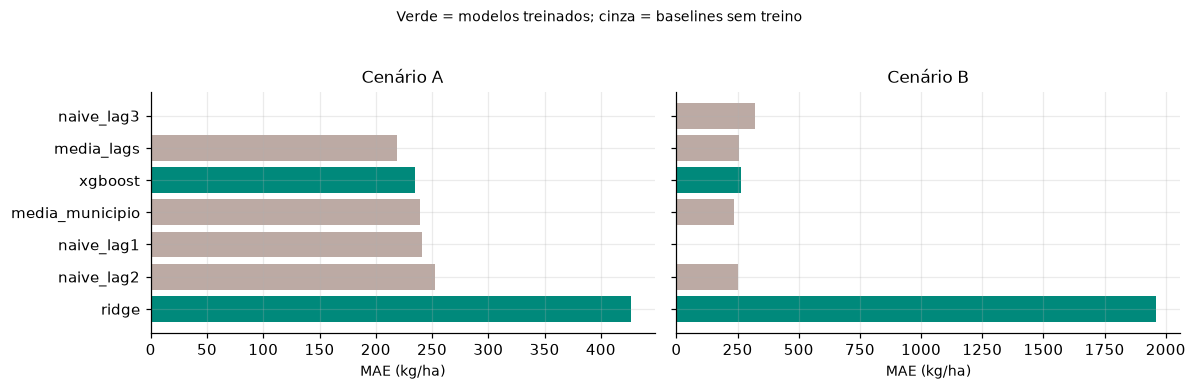

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for a, (res, tt) in zip(ax, [(resA, "Cenário A"), (resB, "Cenário B")]):
    t = tabela(res)
    cols = ["#00897b" if m in ("ridge", "xgboost") else "#bcaaa4" for m in t.index]
    a.barh(t.index[::-1], t.MAE[::-1], color=cols[::-1]); a.set_title(tt); a.set_xlabel("MAE (kg/ha)")
plt.suptitle("Verde = modelos treinados; cinza = baselines sem treino", y=1.03, fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "06_comparacao_modelos.png"); plt.show()

**Como ler:** compare cada modelo treinado (verde) com o melhor baseline (cinza). Um modelo só "ganha" se seu MAE for **claramente** menor que o do melhor baseline.

**Resultado nesta execução:** nenhum modelo treinado bate o melhor baseline em MAE (cenário A: XGBoost 235 × `media_lags` 219 kg/ha; cenário B: XGBoost 264 × `media_municipio` 234 kg/ha). No cenário A o XGBoost empata em RMSE (353 × 355). Ou seja: **a persistência já explica quase tudo o que é previsível** com estes dados — resultado legítimo, não falha do projeto.

**Baselines:** `naive_lag1/2/3` repetem o rendimento de T−1/T−2/T−3; `media_lags` faz a média dos lags disponíveis; `media_municipio` usa a média histórica do município no treino. São **difíceis de bater** porque o rendimento municipal da PAM é muito persistente (estimativas repetidas — notebook 02).

**Atenção ao `ridge`:** se o seu erro for muito maior que o dos baselines, **não é "o modelo ruim"** — é um defeito de extrapolação, investigado na seção 3.

## 2. Erro por ano-alvo

Médias globais escondem o comportamento ano a ano. Abaixo, o MAE por safra de teste para o XGBoost, o ridge e os principais baselines (cenário A).

modelo,media_lags,media_municipio,naive_lag1,naive_lag2,ridge,xgboost
grupo,,,,,,
2017,252.00,259.00,278.00,255.00,732.00,261.00
2018,184.00,218.00,221.00,219.00,"1,299.00",222.00
2019,211.00,271.00,248.00,258.00,234.00,219.00
2020,190.00,224.00,196.00,226.00,229.00,205.00
2021,218.00,233.00,247.00,237.00,228.00,281.00
2022,194.00,186.00,234.00,225.00,229.00,202.00
2023,245.00,233.00,266.00,286.00,343.00,240.00
2024,248.00,272.00,247.00,300.00,262.00,262.00
2025,226.00,259.00,234.00,274.00,228.00,224.00


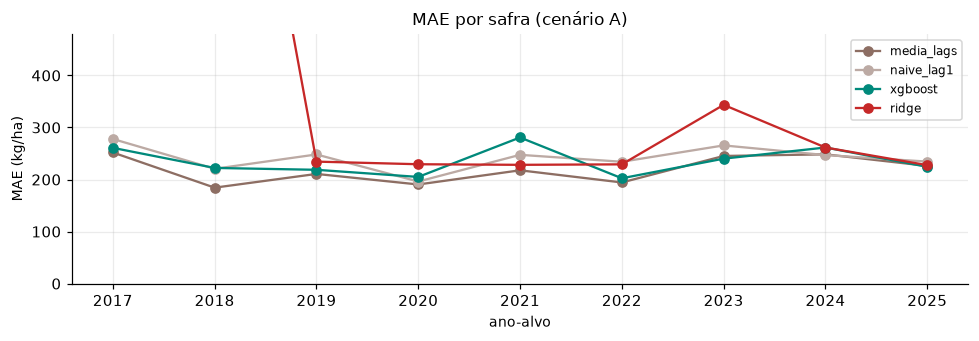

In [5]:
by = M.score_table(M.BacktestResult("A", M.common_subset(resA), resA.features), by_year=True)
pv = by.pivot(index="grupo", columns="modelo", values="MAE")
display(pv.round(0))
fig, ax = plt.subplots(figsize=(9, 3.2))
for m, col in zip(["media_lags", "naive_lag1", "xgboost", "ridge"], ["#8d6e63", "#bcaaa4", "#00897b", "#c62828"]):
    ax.plot(pv.index, pv[m], "o-", color=col, label=m)
ax.set(xlabel="ano-alvo", ylabel="MAE (kg/ha)", title="MAE por safra (cenário A)"); ax.legend(fontsize=8); ax.set_ylim(0, pv.drop(columns="ridge").max().max() * 1.6)
plt.tight_layout(); plt.savefig(FIG / "06_mae_por_ano.png"); plt.show()

**Como ler:** anos atípicos afetam **todos** os modelos juntos (o erro sobe para todos). O eixo vertical foi truncado para o `ridge` não achatar as demais curvas; o valor real do ridge está na tabela.

## 3. Por que o `ridge` falha em certas dobras? Extrapolação de covariáveis de ano

`preco_real_lag1`, `rend_reg_lag*` têm **um único valor por ano** (são iguais para todos os municípios). No treino das primeiras dobras há apenas **3–4 valores distintos** dessas variáveis; o modelo linear ajusta uma inclinação em cima de poucos pontos. Quando o ano de teste traz um valor **fora da faixa vista**, a previsão linear **extrapola**; árvores (XGBoost) não extrapolam: saturam no último valor visto.

In [6]:
dB = M.prepare(panel, "B")
rows = []
for t in range(2017, 2026):
    tr, te = dB[dB.ano < t], dB[dB.ano == t]
    if te.empty: continue
    rows.append({"ano_teste": t, "anos_no_treino": tr.ano.nunique(), "preço treino min": tr.preco_real_lag1.min(), "preço treino max": tr.preco_real_lag1.max(),
                 "preço teste": te.preco_real_lag1.iloc[0], "fora da faixa?": not (tr.preco_real_lag1.min() <= te.preco_real_lag1.iloc[0] <= tr.preco_real_lag1.max())})
ext = pd.DataFrame(rows).set_index("ano_teste")
byB = M.score_table(M.BacktestResult("B", M.common_subset(resB), resB.features), by_year=True).pivot(index="grupo", columns="modelo", values="MAE")
ext["MAE ridge (B)"] = byB.ridge; ext["MAE xgboost (B)"] = byB.xgboost
ext.round(0)

,anos_no_treino,preço treino min,preço treino max,preço teste,fora da faixa?,MAE ridge (B),MAE xgboost (B)
ano_teste,,,,,,,
2017,2,"1,151.00","1,183.00","1,173.00",False,448.00,317.00
2018,3,"1,151.00","1,183.00",958.00,True,"3,842.00",282.00
2019,4,958.00,"1,183.00",929.00,True,"11,405.00",234.00
2020,5,929.00,"1,183.00",955.00,False,218.00,251.00
2021,6,929.00,"1,183.00","1,399.00",True,242.00,252.00
2022,7,929.00,"1,399.00","1,823.00",True,255.00,220.00
2023,8,929.00,"1,823.00","2,001.00",True,297.00,263.00
2024,9,929.00,"2,001.00","1,494.00",False,287.00,301.00
2025,10,929.00,"2,001.00","1,923.00",False,266.00,254.00


**Como ler:** onde `fora da faixa? = True` e o MAE do ridge explode, a causa é **extrapolação linear** de uma covariável de ano. Não é "má sorte": é uma propriedade do desenho (poucos anos, covariável constante entre municípios). Observe também que o fora-da-faixa em 2021–2023 **não** explodiu o erro: com mais anos no treino a inclinação fica mais estável. **Remédios:** remover as covariáveis de ano (as ablações abaixo mostram o ridge voltando a ~230 kg/ha no cenário A sem `rend_reg_lag*` e sem clima), usar árvores, ou limitar (*clip*) ao intervalo do treino (exercício 1).

## 4. Ablações: o que cada grupo de features acrescenta?

Variantes: **completo**; **sem regional** (sem `rend_reg_lag*`); **sem clima**; **sem clima e sem regional**. O MAE é medido no mesmo conjunto de linhas.

In [7]:
variants = {"completo": {}, "sem_regional": dict(with_regional=False), "sem_clima": dict(with_clima=False),
            "sem_clima_sem_regional": dict(with_clima=False, with_regional=False), "sem_preco": dict(with_price=False)}
rows = []
for sc in "AB":
    base = M.backtest(panel, sc)
    best_base = M.common_subset(base)
    bl = min(M.mae(best_base.y, best_base[c]) for c in best_base.columns if c.startswith(("naive", "media")))
    for nm, kw in variants.items():
        r = M.backtest(panel, sc, **kw); c = M.common_subset(r)
        rows.append({"cenário": sc, "variante": nm, "n": len(c), "MAE ridge": M.mae(c.y, c.ridge), "MAE xgboost": M.mae(c.y, c.xgboost),
                     "melhor baseline (MAE)": bl})
abl = pd.DataFrame(rows).set_index(["cenário", "variante"])
abl.round(1)

n  MAE ridge  MAE xgboost  melhor baseline (MAE)
cenário variante                                                                   
A       completo                1080     426.40       235.20                 218.70
        sem_regional            1080     284.40       234.30                 218.70
        sem_clima               1080     423.00       227.00                 218.70
        sem_clima_sem_regional  1080     230.10       229.10                 218.70
        sem_preco               1080     390.60       232.70                 218.70
B       completo                1079   1,961.20       264.10                 234.40
        sem_regional            1079     391.70       263.10                 234.40
        sem_clima               1079   1,271.10       256.90                 234.40
        sem_clima_sem_regional  1079     398.70       254.60                 234.40
        sem_preco               1079     571.40       260.00                 234.40

**Como ler:** diferenças de poucos kg/ha entre variantes **não são interpretáveis** com este *n*. Procure efeitos grandes e consistentes entre os dois modelos e os dois cenários. Se tirar o clima **não piora** o erro, isso é **resultado** (o clima de grade de 55 km, sem informação de manejo, não acrescenta previsão além da persistência), e não uma falha a esconder. Lembre: municípios da mesma célula compartilham o mesmo clima, e só há 9 anos-alvo; o número efetivo de observações climáticas independentes é bem menor que 1 000.

## 5. Incerteza: intervalos conformes (split, por dobras anteriores)

Para cada ano *T*, o intervalo de nível 80% é ŷ ± q, com *q* o quantil de **|resíduos| de todas as dobras anteriores a T** (corrigido por (n+1)). Garantia teórica de cobertura **marginal ≈ 80%** exige trocabilidade — que **não vale** em séries com mudança de regime. Por isso **medimos a cobertura empírica** por ano.

linhas com intervalo  cobertura (nominal 80%)  largura média (kg/ha)
cenário modelo                                                                               
A       xgboost                           953                    80.30                 745.10
        media_lags                        953                    82.30                 774.00
        naive_lag1                        953                    82.00                 852.60
B       xgboost                           952                    82.10                 847.80
        media_municipio                   952                    82.10                 820.10
        naive_lag2                        952                    78.40                 776.80

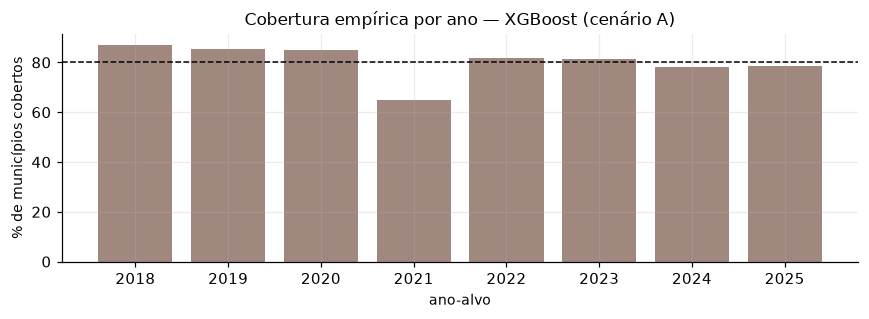

In [8]:
rows = []
for sc, res in (("A", resA), ("B", resB)):
    c = M.common_subset(res)
    for m in ["xgboost", "media_lags" if sc == "A" else "media_municipio", "naive_lag1" if sc == "A" else "naive_lag2"]:
        ci = M.conformal_intervals(c, m, alpha=0.2); cv = M.coverage(ci)
        rows.append({"cenário": sc, "modelo": m, "linhas com intervalo": cv["n"], "cobertura (nominal 80%)": 100 * cv["cobertura"], "largura média (kg/ha)": cv["largura_media"]})
cob = pd.DataFrame(rows).set_index(["cenário", "modelo"]); display(cob.round(1))
ci = M.conformal_intervals(M.common_subset(resA), "xgboost", alpha=0.2)
porano = ci.dropna(subset=["lo"]).groupby("ano").coberto.mean() * 100
fig, ax = plt.subplots(figsize=(8, 3)); ax.bar(porano.index, porano.values, color="#a1887f"); ax.axhline(80, color="k", ls="--", lw=1)
ax.set(ylabel="% de municípios cobertos", xlabel="ano-alvo", title="Cobertura empírica por ano — XGBoost (cenário A)")
plt.tight_layout(); plt.savefig(FIG / "06_cobertura.png"); plt.show()

**Como ler:** a cobertura média ficou próxima do nominal (≈80%), mas **por ano** variou de ≈65% (2021) a ≈87% (2018): os erros são **correlacionados** entre municípios no mesmo ano, e um ano atípico fura o intervalo de muitos municípios ao mesmo tempo. Em decisão de risco, use a **pior** cobertura anual, não a média.

## 6. Produção regional (agregação de municípios)

Produção prevista = Σ (rendimento previsto × área de referência) / 1000, para os municípios elegíveis. Erros municipais de sinais opostos **se compensam** na soma — o erro regional costuma ser **menor** que o municipal em termos relativos.

In [9]:
reg = M.regional_production(resA, ["xgboost", "media_lags", "naive_lag1"])
display(reg.round(1))
print("Erro regional absoluto médio (%):", {m: round(reg[f"{m}_erro_%"].abs().mean(), 1) for m in ["xgboost", "media_lags", "naive_lag1"]})

,ano,n_municipios,obs_t,xgboost,xgboost_erro_%,media_lags,media_lags_erro_%,naive_lag1,naive_lag1_erro_%
0,2017,127,"255,979.00","265,230.60",3.60,"288,648.90",12.80,"332,312.20",29.80
1,2018,123,"334,824.00","279,046.70",-16.70,"289,140.70",-13.60,"255,584.60",-23.70
2,2019,123,"282,032.00","282,403.50",0.10,"298,970.10",6.00,"334,955.50",18.80
3,2020,120,"336,656.00","311,077.10",-7.60,"307,139.50",-8.80,"281,471.60",-16.40
4,2021,120,"310,594.00","322,626.30",3.90,"310,579.10",-0.00,"336,757.40",8.40
5,2022,121,"285,124.00","319,288.70",12.00,"323,417.10",13.40,"310,375.10",8.90
6,2023,117,"300,647.00","294,137.30",-2.20,"296,537.60",-1.40,"285,413.60",-5.10
7,2024,118,"329,795.00","283,461.50",-14.00,"288,919.60",-12.40,"300,579.50",-8.90
8,2025,111,"309,981.00","317,008.90",2.30,"314,124.10",1.30,"328,057.00",5.80


Erro regional absoluto médio (%): {'xgboost': np.float64(6.9), 'media_lags': np.float64(7.7), 'naive_lag1': np.float64(14.0)}


**Como ler:** o erro regional absoluto médio é ≈6,9% (XGBoost) e ≈14,0% (`naive_lag1`), contra ≈15% de sMAPE municipal: a agregação compensa erros de sinais opostos. Mas os anos de safra alta/baixa (2018, 2024) continuam subestimados em −14% a −17%: o erro é **sistemático**, não aleatório. O `_erro_%` é o viés da produção regional prevista. Use-o com cuidado: o painel cobre só municípios **elegíveis** (área ≥ limiar e histórico completo), e **não** toda a produção paulista.

## 7. Por que validação aleatória é enganosa (vazamento temporal)

Demonstração: o **mesmo** XGBoost, com as mesmas features do cenário A, avaliado por **K-fold aleatório** (linhas de qualquer ano em treino e teste) e pela validação temporal. Na validação aleatória, o treino contém o **ano seguinte** e municípios vizinhos do mesmo ano, e o modelo "olha o futuro".

In [10]:
from sklearn.model_selection import KFold
from sklearn.base import clone
dA = M.prepare(panel, "A"); fA = M.feature_list("A"); dA = dA.dropna(subset=[c for c in fA if c.startswith("rend_reg")])
xg = M.make_models(0)["xgboost"]
test_years = dA[dA.ano >= 2017]
maes_rand = []
for tr_i, te_i in KFold(5, shuffle=True, random_state=0).split(dA):
    mm = clone(xg).fit(dA.iloc[tr_i][fA], dA.iloc[tr_i].rendimento_kg_ha)
    te = dA.iloc[te_i]; te = te[te.ano >= 2017]
    maes_rand.append(M.mae(te.rendimento_kg_ha, mm.predict(te[fA])))
c = M.common_subset(resA)
print(f"MAE com K-fold ALEATÓRIO (linhas de teste de 2017+): {np.mean(maes_rand):.0f} kg/ha")
print(f"MAE com validação TEMPORAL honesta (2017+):          {M.mae(c.y, c.xgboost):.0f} kg/ha")

MAE com K-fold ALEATÓRIO (linhas de teste de 2017+): 218 kg/ha
MAE com validação TEMPORAL honesta (2017+):          235 kg/ha


**Como ler:** a validação aleatória dá erro **menor** (≈7% aqui), na direção esperada. A diferença é modesta neste caso porque os lags de rendimento já carregam a persistência; ela seria maior com alvos mais dependentes da vizinhança temporal. O ponto metodológico permanece: o otimismo é injetado **sem** que você perceba. Em projetos reais esse otimismo vira "modelo que funcionou em teste e falhou em produção". **Nunca** use K-fold aleatório em dados com estrutura temporal.

## 8. O que o XGBoost usou? (com muita cautela)

Importância por *gain* mostra quais variáveis as árvores usaram, **não** o que causa o rendimento. Variáveis correlacionadas dividem importância; covariáveis de ano (poucos valores) podem ser usadas como "identificador de ano".

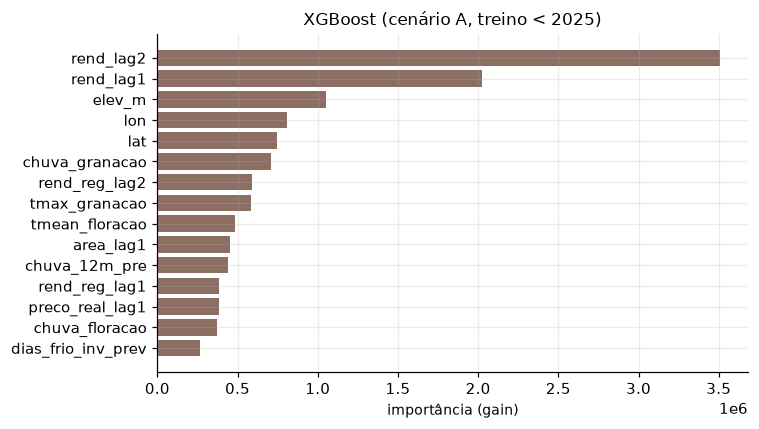

rend_lag2        27.40
rend_lag1        15.80
elev_m            8.20
lon               6.30
lat               5.80
chuva_granacao    5.50


In [11]:
dtr = dA[dA.ano < 2025]; mm = clone(xg).fit(dtr[fA], dtr.rendimento_kg_ha)
imp = pd.Series(mm.get_booster().get_score(importance_type="gain")).reindex(fA).fillna(0).sort_values()
fig, ax = plt.subplots(figsize=(7, 4)); ax.barh(imp.index, imp.values, color="#8d6e63"); ax.set_xlabel("importância (gain)")
ax.set_title("XGBoost (cenário A, treino < 2025)"); plt.tight_layout(); plt.savefig(FIG / "06_importancia_xgb.png"); plt.show()
print((100 * imp[::-1] / imp.sum()).round(1).head(6).to_string())

**Como ler:** os dois lags de rendimento somam ≈43% do *gain* (e `rend_lag2` pesa mais que `rend_lag1`, compatível com a alternância bienal vista no notebook 05): o modelo está basicamente **aprendendo persistência** — coerente com os baselines serem competitivos. Não leia "chuva importa X%": a importância depende do modelo e dos dados, e **não é efeito causal**.

## 9. Registro de experimentos (MLflow, opcional)

Com `USE_MLFLOW=1` e a biblioteca instalada, as métricas dos cenários são registradas em `mlflow.db` (SQLite; ignorado pelo git — o backend de arquivos `mlruns/` foi descontinuado nas versões recentes do MLflow). Sem a variável, esta etapa é pulada: **o projeto não depende de MLflow**.

In [12]:
if config.USE_MLFLOW:
    import mlflow
    mlflow.set_tracking_uri(f"sqlite:///{config.ROOT / 'mlflow.db'}"); mlflow.set_experiment("coffee-bdi-previsao")
    for sc, res in (("A", resA), ("B", resB)):
        t = tabela(res)
        for m, r in t.iterrows():
            with mlflow.start_run(run_name=f"{sc}-{m}"):
                mlflow.log_params({"cenario": sc, "modelo": m, "n_features": len(res.features)})
                mlflow.log_metrics({"MAE": r.MAE, "RMSE": r.RMSE, "sMAPE": r["sMAPE_%"], "WAPE": r["WAPE_%"]})
    print("Registrado em", config.ROOT / "mlflow.db", "(visualizar: mlflow ui --backend-store-uri sqlite:///mlflow.db)")
else:
    print("USE_MLFLOW não definido: registro de experimentos pulado (definido em .env ou ambiente).")

USE_MLFLOW não definido: registro de experimentos pulado (definido em .env ou ambiente).


## 10. Resumo interpretativo

| Pergunta | Evidência | Limite |
|---|---|---|
| Modelo treinado bate baseline simples? | seção 1 (compare verde × cinza) | ~1 000 linhas, poucos anos distintos |
| Clima melhora a previsão? | seção 4 (ablações) | clima de grade ~55 km; ano compartilhado entre municípios |
| Os intervalos são confiáveis? | seção 5: cobertura **por ano** | erros correlacionados no tempo |
| Validação aleatória é segura? | seção 7 | **não**: infla o desempenho |
| O erro regional é menor que o municipal? | seção 6 | só municípios elegíveis |

## Exercícios
1. Restrinja o `ridge` com *clip* nas covariáveis de ano e refaça a seção 3: o erro de 2018–2019 desaparece?
2. Altere `first_test` para 2019 e 2021: o ranking entre XGBoost e baselines muda?
3. Acrescente um baseline `media_lags_ponderada` e compare com o XGBoost via MAE por ano.
4. Troque `alpha` por 0,1 e 0,5 e compare cobertura nominal × observada.
5. Por que o erro de sMAPE pode ser enganoso quando o rendimento previsto é próximo de zero?